# Monocular depth 3: from depth maps to 3D point clouds

Robots plan and act in 3D. A depth map becomes useful once it is **back-projected** into a point
cloud in the camera frame, and then into the world frame using the camera pose. This notebook
does that for the Kinect depth and for three monocular models, measures the 3D error directly,
and fuses several frames with the motion-capture poses of TUM RGB-D.

**What this notebook does**
1. Back-projects the sensor depth of a TUM `fr1_desk` frame into a coloured point cloud (OpenCV camera frame).
2. Does the same for DA3METRIC-LARGE and DA-V2 Metric-Indoor (raw metres), and for DA3-BASE after median scaling (an oracle scale, for reference).
3. Measures cloud-to-cloud accuracy, completeness, Chamfer distance and F-score@5 cm, and shows where *flying pixels* come from.
4. Fuses 9 frames into the world frame with ground-truth poses and compares the fused monocular map with the fused sensor map. Exports `.ply` files.

**What you'll learn**
- The back-projection equation, the camera-frame convention, and why *z-depth* is not *range*.
- How per-pixel depth errors turn into 3D artefacts: scale-stretched scenes, smeared boundaries, and layered surfaces when frames disagree on scale.
- How to quantify 3D quality with nearest-neighbour statistics rather than 2D metrics alone.

**Prerequisites**: notebooks 01-02, and SE(3) poses (project 07). Data and weights come from `make data-08_monocular_depth`.

## Setup

In [1]:
# --- Setup: imports, device, repo-relative paths and plotting style ---
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cvlab import device as cv_device
from cvlab import viz
from cvlab.geometry import transform_points
from cvlab.io import outputs_dir, project_dir, repo_root
from cvlab.pointcloud import depth_to_points, voxel_downsample, write_ply

device = cv_device.setup(seed=0)
viz.set_style()
PROJECT = "08_monocular_depth"
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import mono_depth as md  # project helpers: models, alignment, cloud metrics

OUT = outputs_dir(PROJECT, create=True)  # gitignored: .ply files
print("outputs:", OUT.relative_to(repo_root()))

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
outputs: outputs/08_monocular_depth


## Back-projection

For a pixel $(u, v)$ with depth $z$ (distance along the optical axis, which is what both the
Kinect and the networks predict), the 3D point in the **OpenCV camera frame** ($x$ right, $y$
down, $z$ forward) is

$$\mathbf X = z\,K^{-1}\begin{bmatrix}u\\ v\\ 1\end{bmatrix}
= \begin{bmatrix} (u - c_x)\,z / f_x \\ (v - c_y)\,z / f_y \\ z \end{bmatrix}.$$

Two consequences matter in practice.
- A depth error $\Delta z$ moves the point along its viewing ray, so a **global scale error stretches the whole scene radially** away from the camera.
- The *range* $\|\mathbf X\|$ is larger than $z$ off-axis. Some sensors (ToF, lidar) return range, not $z$, and mixing the two up bends planes.

`cvlab.pointcloud.depth_to_points` implements this equation, with optional colours and a stride for subsampling.
We use the calibrated fr1 intrinsics for every cloud, so all clouds share the same (slightly
distorted) geometry and differ only by their depth.

GT cloud: 58534 points (stride 2) | x -1.77..1.31 m, z 0.90..3.76 m


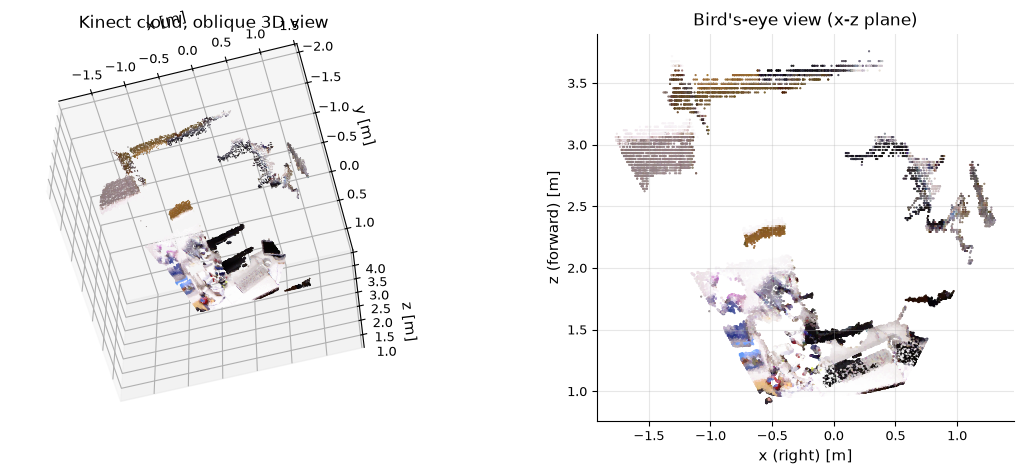

In [2]:
# --- Back-project the Kinect depth of one frame into a coloured point cloud ---
seq = md.load_tum("fr1_desk")
FRAME = 450
rgb, gt = seq.rgb(FRAME), seq.depth(FRAME)
K = seq.camera.K
gt_pts, gt_col = depth_to_points(gt, K, rgb=rgb, stride=2, min_depth=md.MIN_DEPTH,
                                 max_depth=md.MAX_DEPTH)  # (N, 3) metres, camera frame
print(f"GT cloud: {len(gt_pts)} points (stride 2) | x {gt_pts[:, 0].min():.2f}..{gt_pts[:, 0].max():.2f} m, "
      f"z {gt_pts[:, 2].min():.2f}..{gt_pts[:, 2].max():.2f} m")

fig = plt.figure(figsize=(12, 4.6))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
viz.plot_point_cloud(gt_pts, gt_col, ax=ax1, max_points=40000, size=0.6, elev=-60, azim=-75)
ax1.set_title("Kinect cloud, oblique 3D view", y=1.08)
ax2 = fig.add_subplot(1, 2, 2)
sub = np.random.default_rng(0).choice(len(gt_pts), 40000, replace=False)
ax2.scatter(gt_pts[sub, 0], gt_pts[sub, 2], c=gt_col[sub], s=0.3)
ax2.set(xlabel="x (right) [m]", ylabel="z (forward) [m]", title="Bird's-eye view (x-z plane)")
ax2.set_aspect("equal")
plt.show()

## Monocular clouds

We back-project three predictions with the same $K$:
- **DA3METRIC-LARGE**, raw metres. Nothing from the sensor is used, which is the realistic robot setting.
- **DA-V2 Metric-Indoor Small**, raw metres.
- **DA3-BASE** after median scaling to the sensor. This is an *oracle* scale and shows the shape quality on its own.

The models are run one at a time and released afterwards.

In [3]:
# --- Predict, align and back-project three models on the same frame ---
cloud_keys = {"da3metric-large": "none", "da2-metric-indoor-small": "none", "da3-base": "median"}
depths, clouds = {}, {}
for key, proto in cloud_keys.items():
    model = md.DepthModel(key, device=str(device))
    p = model.predict(rgb, K)
    r = md.evaluate_frame(p.values, p.output, gt, [proto])[proto]
    # Back-project only pixels that also have sensor depth, so both clouds cover the same rays.
    depths[key] = r["depth"]
    clouds[key] = depth_to_points(r["depth"], K, rgb=rgb, stride=2, mask=md.valid_mask(gt))
    print(f"{md.MODELS[key].label:>26s} ({md.PROTOCOL_LABELS[proto]}): AbsRel {r['abs_rel']:.3f}, "
          f"scale {r['scale']:.3f}, {len(clouds[key][0])} points")
    del model
    md.free_cuda()

           DA3Metric-Large (raw metric): AbsRel 0.127, scale 1.000, 58534 points


 DA-V2 Metric-Indoor Small (raw metric): AbsRel 0.169, scale 1.000, 58534 points


                  DA3-Base (median scale): AbsRel 0.075, scale 1.791, 58534 points


### Bird's-eye comparison

The grey points are the Kinect cloud and the coloured points are the prediction. Because a scale
error moves points along their rays, a model that is 10 % too far pushes the desk edge and the
monitors 10 % further back. Boundary smearing shows up as streaks pointing towards the camera at the origin.

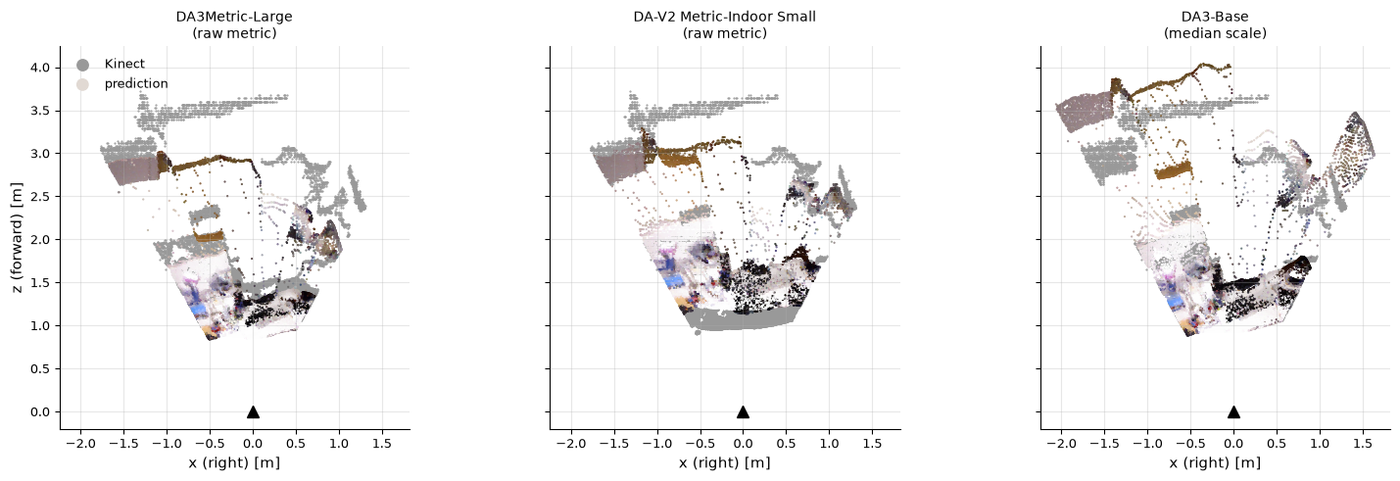

In [4]:
# --- Overlay each predicted cloud on the sensor cloud (top-down x-z view) ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True, sharey=True)
rng = np.random.default_rng(0)
g = gt_pts[rng.choice(len(gt_pts), 30000, replace=False)]
for ax, (key, proto) in zip(axes, cloud_keys.items()):
    pts, col = clouds[key]
    sel = rng.choice(len(pts), 30000, replace=False)
    ax.scatter(g[:, 0], g[:, 2], s=0.3, c="0.6", label="Kinect")
    ax.scatter(pts[sel, 0], pts[sel, 2], s=0.3, c=col[sel], label="prediction")
    ax.plot(0, 0, "k^", ms=8)
    ax.set_title(f"{md.MODELS[key].label}\n({md.PROTOCOL_LABELS[proto]})", fontsize=10)
    ax.set_xlabel("x (right) [m]")
    ax.set_aspect("equal")
axes[0].set_ylabel("z (forward) [m]")
axes[0].legend(markerscale=15, loc="upper left")
viz.savefig(fig, PROJECT, "pointcloud_topdown")
plt.show()

## 3D error metrics and flying pixels

For every predicted point we find the nearest Kinect point, and the reverse. Writing $P$ for the
predicted cloud and $G$ for the Kinect cloud:

$$\text{acc} = \operatorname{mean}_{p\in P}\min_{g\in G}\|p-g\|, \quad
\text{comp} = \operatorname{mean}_{g\in G}\min_{p\in P}\|p-g\|, \quad
\text{Chamfer} = \tfrac12(\text{acc} + \text{comp}),$$

and the **F-score@5 cm** is the harmonic mean of precision (the share of predicted points within
5 cm of $G$) and recall (the share of $G$ within 5 cm of $P$). Both clouds are first voxel-downsampled at 1 cm, so dense regions do not dominate.

**Flying pixels**: at a depth discontinuity, for example a monitor edge in front of a wall, a
network outputs a smooth ramp between foreground and background. Back-projected, that ramp becomes
points floating in empty space. They are a real hazard for collision checking and grasping.
Colouring the predicted points by their nearest-neighbour error makes them visible.

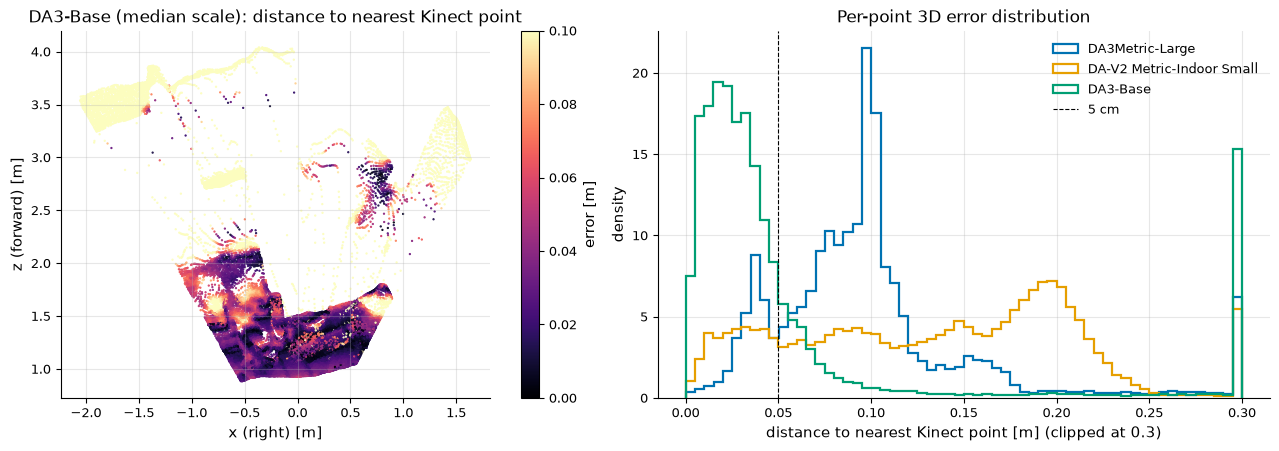

model,protocol,accuracy_mean_m,accuracy_median_m,completeness_mean_m,chamfer_m,precision@5cm,recall@5cm,fscore@5cm
DA3Metric-Large,raw metric,0.117,0.097,0.175,0.146,0.147,0.112,0.127
DA-V2 Metric-Indoor Small,raw metric,0.129,0.122,0.136,0.132,0.231,0.279,0.253
DA3-Base,median scale,0.114,0.040,0.064,0.089,0.588,0.602,0.595


In [5]:
# --- Cloud-to-cloud metrics (1 cm voxels) and the error of each predicted point ---
gt_vox, _ = voxel_downsample(gt_pts, 0.01)
rows, errs = [], {}
for key, proto in cloud_keys.items():
    pv, _ = voxel_downsample(clouds[key][0], 0.01)
    stats = md.chamfer_stats(pv, gt_vox, thresh=0.05)
    rows.append({"model": md.MODELS[key].label, "protocol": md.PROTOCOL_LABELS[proto], **stats})
    errs[key] = md.nn_distances(clouds[key][0], gt_vox)  # per predicted point [m]
cloud_df = pd.DataFrame(rows)

key = "da3-base"  # oracle scale: the remaining errors are shape errors (edges, thin parts)
pts, e = clouds[key][0], errs[key]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
sel = np.random.default_rng(1).choice(len(pts), 40000, replace=False)
sc = axes[0].scatter(pts[sel, 0], pts[sel, 2], c=e[sel], s=0.4, cmap="magma", vmin=0, vmax=0.1)
axes[0].set(xlabel="x (right) [m]", ylabel="z (forward) [m]",
            title=f"{md.MODELS[key].label} (median scale): distance to nearest Kinect point")
axes[0].set_aspect("equal")
fig.colorbar(sc, ax=axes[0], label="error [m]")
for i, (k, ev) in enumerate(errs.items()):
    axes[1].hist(np.clip(ev, 0, 0.3), bins=60, histtype="step", lw=1.6, density=True,
                 color=viz.color(i, unit=True), label=md.MODELS[k].label)
axes[1].axvline(0.05, color="k", ls="--", lw=0.8, label="5 cm")
axes[1].set(xlabel="distance to nearest Kinect point [m] (clipped at 0.3)", ylabel="density",
            title="Per-point 3D error distribution")
axes[1].legend()
plt.show()
cloud_df.style.format(precision=3).hide(axis="index")

## Multi-frame fusion with ground-truth poses

TUM provides the camera-to-world pose $T_{wc}$ of every frame, from motion capture. A point in
camera frame $c$ maps to the world as

$$\mathbf X_w = R_{wc}\,\mathbf X_c + \mathbf t_{wc}.$$

Fusing several frames is the simplest mapping system. With perfect depth, all frames land on the
same surfaces. With per-frame monocular depth, every frame has its own scale error and shape
error, so the same desk appears as several **layers**. This is why monocular depth needs either
temporal consistency (video-depth models, multi-view models such as DA3 any-view in project 10)
or fusion with a SLAM scale estimate.

We fuse 9 frames spanning about 2.7 s around frame 450 (every 10th frame). The fused clouds are
voxel-downsampled at 1 cm and exported as `.ply` files to `outputs/08_monocular_depth/`, which can be opened in MeshLab or CloudCompare.

In [6]:
# --- Fuse 9 frames in the world frame: Kinect vs DA3METRIC-LARGE (raw metres) ---
fuse_frames = list(range(FRAME - 40, FRAME + 41, 10))
model = md.DepthModel("da3metric-large", device=str(device))
world = {"Kinect": [], "DA3METRIC-LARGE": []}
colors = {"Kinect": [], "DA3METRIC-LARGE": []}
frame_scales = []
for i in fuse_frames:
    rgb_i, gt_i, T_wc = seq.rgb(i), seq.depth(i), seq.gt_poses[i]
    pred = model.predict(rgb_i, K).values
    frame_scales.append(md.evaluate_frame(pred, "metric", gt_i, ["median"])["median"]["scale"])
    for name, depth in [("Kinect", gt_i), ("DA3METRIC-LARGE", pred)]:
        pts, col = depth_to_points(depth, K, rgb=rgb_i, stride=2, mask=md.valid_mask(gt_i))
        world[name].append(transform_points(T_wc, pts))  # camera -> world
        colors[name].append(col)
del model
md.free_cuda()

fused = {}
for name in world:
    fused[name] = voxel_downsample(np.concatenate(world[name]), 0.01, np.concatenate(colors[name]))
    path = write_ply(OUT / f"fused_{name.lower().replace('-', '_')}.ply", *fused[name])
    print(f"{name:>16s}: {len(fused[name][0])} points after 1 cm voxels -> {path.relative_to(repo_root())}")
print("per-frame metric scale error s_t = median(z*)/median(z):", np.round(frame_scales, 3))

          Kinect: 182998 points after 1 cm voxels -> outputs/08_monocular_depth/fused_kinect.ply


 DA3METRIC-LARGE: 175233 points after 1 cm voxels -> outputs/08_monocular_depth/fused_da3metric_large.ply
per-frame metric scale error s_t = median(z*)/median(z): [1.099 1.072 1.071 1.132 1.101 1.094 1.112 1.037 1.016]


## Results

The first figure shows the fused maps from above and from the side, with the camera centres
drawn in red. The motion-capture world frame has $z$ pointing up, so the floor lies at $z_w \approx 0$
and the desk top at about 0.75 m. The table collects the 3D metrics for the single frame and for the fused 9-frame map.

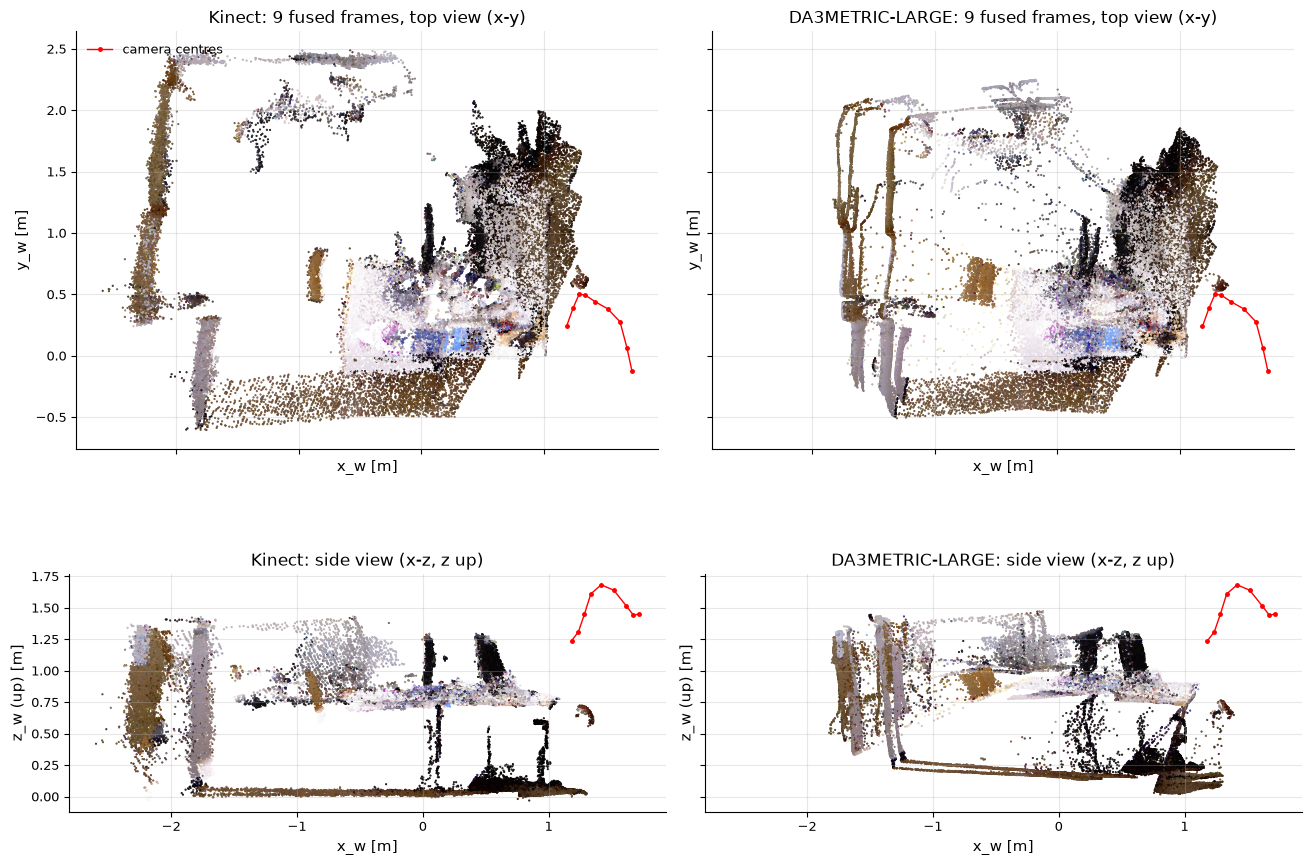

In [7]:
# --- Fused maps: Kinect vs DA3METRIC-LARGE, two orthographic views + camera centres ---
cams = np.stack([seq.gt_poses[i][:3, 3] for i in fuse_frames])
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, sharey="row")
rng = np.random.default_rng(0)
for col, name in enumerate(["Kinect", "DA3METRIC-LARGE"]):
    pts, c = fused[name]
    sel = rng.choice(len(pts), min(60000, len(pts)), replace=False)
    for row, (a, b, lab) in enumerate([(0, 1, ("x_w [m]", "y_w [m]")), (0, 2, ("x_w [m]", "z_w (up) [m]"))]):
        ax = axes[row, col]
        ax.scatter(pts[sel, a], pts[sel, b], c=c[sel], s=0.3)
        ax.plot(cams[:, a], cams[:, b], "r.-", lw=1, ms=5, label="camera centres")
        ax.set(xlabel=lab[0], ylabel=lab[1])
        ax.set_aspect("equal")
    axes[0, col].set_title(f"{name}: {len(fuse_frames)} fused frames, top view (x-y)")
    axes[1, col].set_title(f"{name}: side view (x-z, z up)")
axes[0, 0].legend(loc="upper left", markerscale=1)
viz.savefig(fig, PROJECT, "fusion_views")
plt.show()

The 3D summary table follows. The fused rows compare the 9-frame DA3METRIC-LARGE map with the 9-frame Kinect map.

In [8]:
# --- 3D summary table: single frame (3 models) + fused 9-frame map ---
fstats = md.chamfer_stats(fused["DA3METRIC-LARGE"][0], fused["Kinect"][0], thresh=0.05)
rows3d = cloud_df.assign(setting=f"frame {FRAME}")
rows3d = pd.concat([rows3d, pd.DataFrame([{"model": "DA3Metric-Large", "protocol": "raw metric",
                                           "setting": f"{len(fuse_frames)} fused frames", **fstats}])])
cols = ["setting", "model", "protocol", "accuracy_mean_m", "completeness_mean_m", "chamfer_m",
        "precision@5cm", "recall@5cm", "fscore@5cm"]
rows3d = rows3d[cols].reset_index(drop=True)
rows3d.style.format(precision=3).hide(axis="index")

setting,model,protocol,accuracy_mean_m,completeness_mean_m,chamfer_m,precision@5cm,recall@5cm,fscore@5cm
frame 450,DA3Metric-Large,raw metric,0.117,0.175,0.146,0.147,0.112,0.127
frame 450,DA-V2 Metric-Indoor Small,raw metric,0.129,0.136,0.132,0.231,0.279,0.253
frame 450,DA3-Base,median scale,0.114,0.064,0.089,0.588,0.602,0.595
9 fused frames,DA3Metric-Large,raw metric,0.114,0.119,0.117,0.386,0.434,0.408


### Takeaways

- **A good 2D score is not a good 3D score.** On frame 450, DA3METRIC-LARGE has a raw AbsRel of
  0.127, yet only 14.7 % of its points lie within 5 cm of the Kinect cloud (precision@5 cm 0.147,
  F-score 0.127). At the 1.27 m median depth of this frame, a 12.7 % relative error is about 16 cm
  along each viewing ray, roughly three times the 5 cm threshold. Grasping and collision checking need
  centimetres, and raw monocular metric depth does not deliver them.
- **A global scale error stretches the scene along the rays.** DA3METRIC-LARGE's median scale on this
  frame is 1.101 (the fifth value printed by the fusion cell), so its cloud is pulled about 9 % toward
  the camera in the bird's-eye view while the layout (desk, monitors, back wall) stays correct.
  DA-V2 Metric-Indoor scores better in 3D on *this* frame (Chamfer 0.132 m vs 0.146 m), but its raw
  AbsRel over the 96-frame benchmark is 0.398 (notebook 02). A single frame is anecdotal.
- **Flying pixels make a heavy tail.** With an oracle scale, DA3-BASE gives the best single-frame cloud
  (Chamfer 0.089 m, F-score 0.595), but its mean accuracy (0.114 m) is almost three times its median
  (0.040 m). The tail comes from points interpolated across depth discontinuities, visible as streaks
  along the viewing rays. Exercise 1 tries a simple depth-gradient filter.
- **Fusion exposes frame-to-frame scale inconsistency.** The nine DA3METRIC-LARGE frames need median
  scales between 1.016 and 1.132, so the same surfaces land at different depths. In the fused map, walls
  appear doubled, and the floor rises above $z_w \approx 0$ and tilts, because every point is pulled
  toward a camera that sits well above the floor. Against the fused Kinect map, the result is a Chamfer
  distance of 0.117 m and an F-score@5 cm of 0.408. The F-score is higher than the single-frame value
  partly because a denser reference makes nearest neighbours easier to find, so compare F-scores only
  within one setting. Exercise 2 separates the scale error from the shape error.
- **For a robot**, raw monocular metric depth is enough for coarse layout (where the desk, walls and
  large objects are), not for centimetre-level 3D. Pair it with a scale source (stereo, visual-inertial
  odometry, a few depth-sensor points or an object of known size) and with temporally consistent or
  multi-view depth (project 10).

## Exercises

Solutions: `projects/08_monocular_depth/solutions/solutions_03.py`.

**Exercise 1: a flying-pixel filter.** Remove predicted pixels whose relative depth gradient is large,
$\|\nabla \hat z\| / \hat z > \tau$, before back-projecting. Sweep $\tau \in \{0.02, 0.05, 0.1\}$
for DA3-BASE (median scale) and report the accuracy, completeness and the share of removed points. What is the trade-off?

In [9]:
# --- Exercise 1: depth-discontinuity (flying pixel) filter ---
# TODO: grad = np.hypot(*np.gradient(depths["da3-base"])) / depths["da3-base"]; keep = grad < tau;
# back-project with mask=keep & md.valid_mask(gt) and recompute md.chamfer_stats.

**Exercise 2: what makes the fused map consistent?** Repeat the 9-frame fusion with
(a) DA3METRIC-LARGE scaled per frame by its median scale (oracle), and (b) DA3METRIC-LARGE with one scale
for all frames (the mean of `frame_scales`). Compare F-score@5 cm against the fused Kinect map. Which error dominates, scale or shape?

In [10]:
# --- Exercise 2: fusion with per-frame vs single global scale correction ---
# TODO: re-run the fusion loop, multiplying each prediction by frame_scales[j] (a) or by
# np.mean(frame_scales) (b), and evaluate md.chamfer_stats against fused["Kinect"][0].

**Exercise 3: how much do the intrinsics matter in 3D?** Back-project the *Kinect* depth twice,
with the calibrated fr1 $K$ and with the ROS default ($f = 525$, $c = (319.5, 239.5)$). Report
the Chamfer distance between the two clouds, and the largest point displacement. Which part of the image moves most, and why?

In [11]:
# --- Exercise 3: calibrated vs default intrinsics for back-projection ---
# TODO: K_ros = np.array([[525, 0, 319.5], [0, 525, 239.5], [0, 0, 1]]); back-project gt with both
# (same pixels, stride 1) and compare corresponding points directly (they share pixel order).